# Машинное обучение, ФКН ВШЭ

# Практическое задание 11. Несбалансированные задачи

## Общая информация
Дата выдачи: 23.04.2024

Мягкий дедлайн: 13.05.2024 23:59 MSK

Жесткий дедлайн: 18.05.2024 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-xx-Username.ipynb

Username — ваша фамилия и имя на латинице именно в таком порядке

## О задании

В этом задании мы разберем основные техники работы в задачах, где один из классов занимает существенно меньшую долю выборки, чем остальные. Для простоты мы обойдемся бинарной задачей, тем не менее, во многом данные методы можно перенести и на задачи с б**о**льшим числом классов. Кроме того, вы получите очередной бесценный опыт исследования случайной библиотеки случайных индусов с нуля.

In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')

from tqdm.auto import tqdm
np.random.seed(42)

**Задание -1 (1 балл)**. EDA

В качестве данных для нашей работы возьмем выложенный на kaggle датасет транзакций, в котором нужно выискивать мошеннические проводки: [клик](https://www.kaggle.com/mlg-ulb/creditcardfraud). Данная задача по определению подходит под несбалансированную, что можно сказать даже без наличия каких-либо данных (понятно, что среди всех транзакций клиентов очень малая часть будет мошеннической).

Загрузим данные, проведем некоторые классические манипуляции.

In [2]:
import kaggle
kaggle.api.authenticate()
kaggle.api.dataset_download_files("mlg-ulb/creditcardfraud", path='./data', unzip=True)

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


In [3]:
df = pd.read_csv('data/creditcard.csv')

In [4]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,-1.593105,2.711941,-0.689256,4.626942,-0.924459,1.107641,1.991691,0.510632,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,-0.150189,0.915802,1.214756,-0.675143,1.164931,-0.711757,-0.025693,-1.221179,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,0.411614,0.063119,-0.183699,-0.510602,1.329284,0.140716,0.313502,0.395652,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,-1.933849,-0.962886,-1.042082,0.449624,1.962563,-0.608577,0.509928,1.113981,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


Наши данные были анонимизированы. Мы имеем 30 признаков, из которых 28 - это результаты PCA-преобразования на исходном датасете. Еще 2 признака представляют собой время в секундах, прошедшее с момента первой транзакции в датасете, и размер транзакции. Скажите, какова доля положительных объектов в выборке?

In [5]:
#your code here
print(df["Class"].mean())

0.001727485630620034


Начнем с обработки времени. Секунды сами по себе не несут большой информации о зависимостях в данных, попробуйте по ним создать признаки "час" (от 0 до 23) и "день" (от 0 до ...) в аналогичной манере (принимая первый объект выборки за начальную точку). Сколько дней покрывают данные?

In [6]:
#your code here
df["hour"] = (df["Time"] // 3600) % 24
df["day"] = (df["Time"] // (3600 * 24))
print(df["day"].agg(["min", "max"]))

min    0.0
max    1.0
Name: day, dtype: float64


Постройте следующие графики:

1. Распределение числа транзакций по каждому часу (line-plot).
2. Распределение доли мошеннических транзакций по каждому часу (line-plot)
3. То же самое для дней (здесь можно использовать bar-plot, так как дней должно быть немного).

Какие выводы можно сделать из графиков? На ваш взгляд, как можно связать полученные нами часы с реальными часами в сутках?

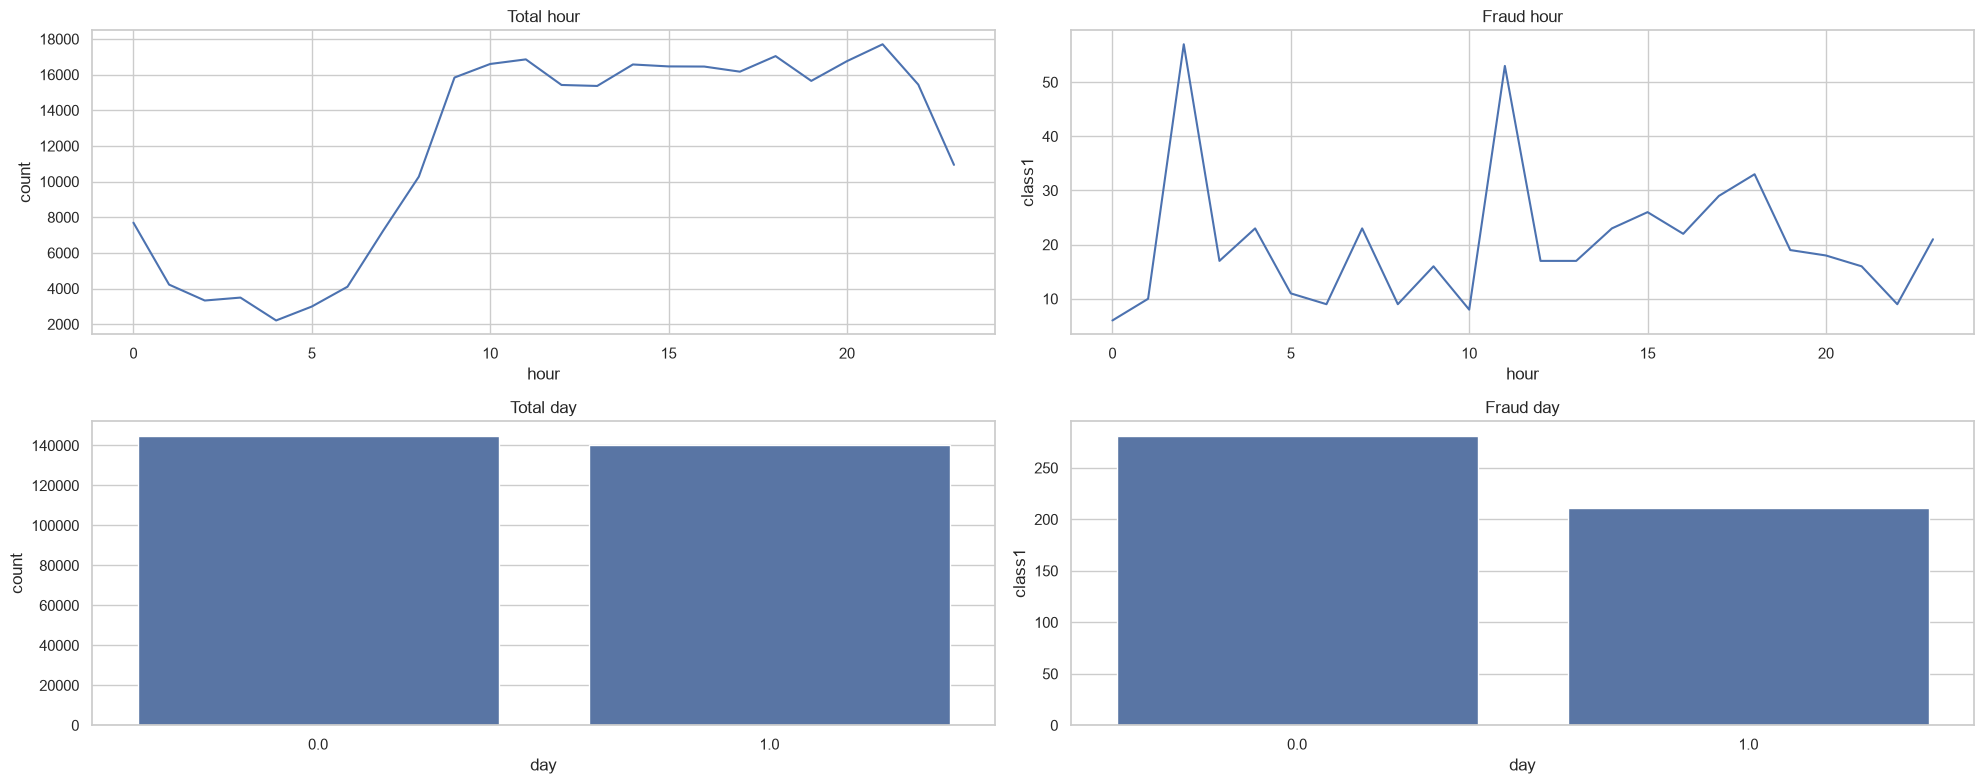

In [7]:
#your code here
res_df = df.groupby("hour")["Class"].agg(["mean", "count"])
res_df["class1"] = res_df["mean"] * res_df["count"]
fig, ax = plt.subplots(2, 2, figsize=(20, 8))
sns.lineplot(res_df, x="hour", y="count", ax=ax[0, 0])
sns.lineplot(res_df, x="hour", y="class1", ax=ax[0, 1])
ax[0, 0].set_title("Total hour")
ax[0, 1].set_title("Fraud hour")
ax[1, 0].set_title("Total day")
ax[1, 1].set_title("Fraud day")

res_df = df.groupby("day")["Class"].agg(["mean", "count"])
res_df["class1"] = res_df["mean"] * res_df["count"]
sns.barplot(res_df, x="day", y="count", ax=ax[1, 0])
sns.barplot(res_df, x="day", y="class1", ax=ax[1, 1])
plt.tight_layout()
plt.show()

С часов 5-10 сильно увеличивается общее количество транзакций, и немного увеличивается количивается мошеннических операций.

С анонимизированными признаками вряд ли можно придумать что-то интересное. Попробуйте (например, с помощью корреляции?) выбрать несколько наиболее важных признаков и поглядеть на различия в их распределении для разных классов.

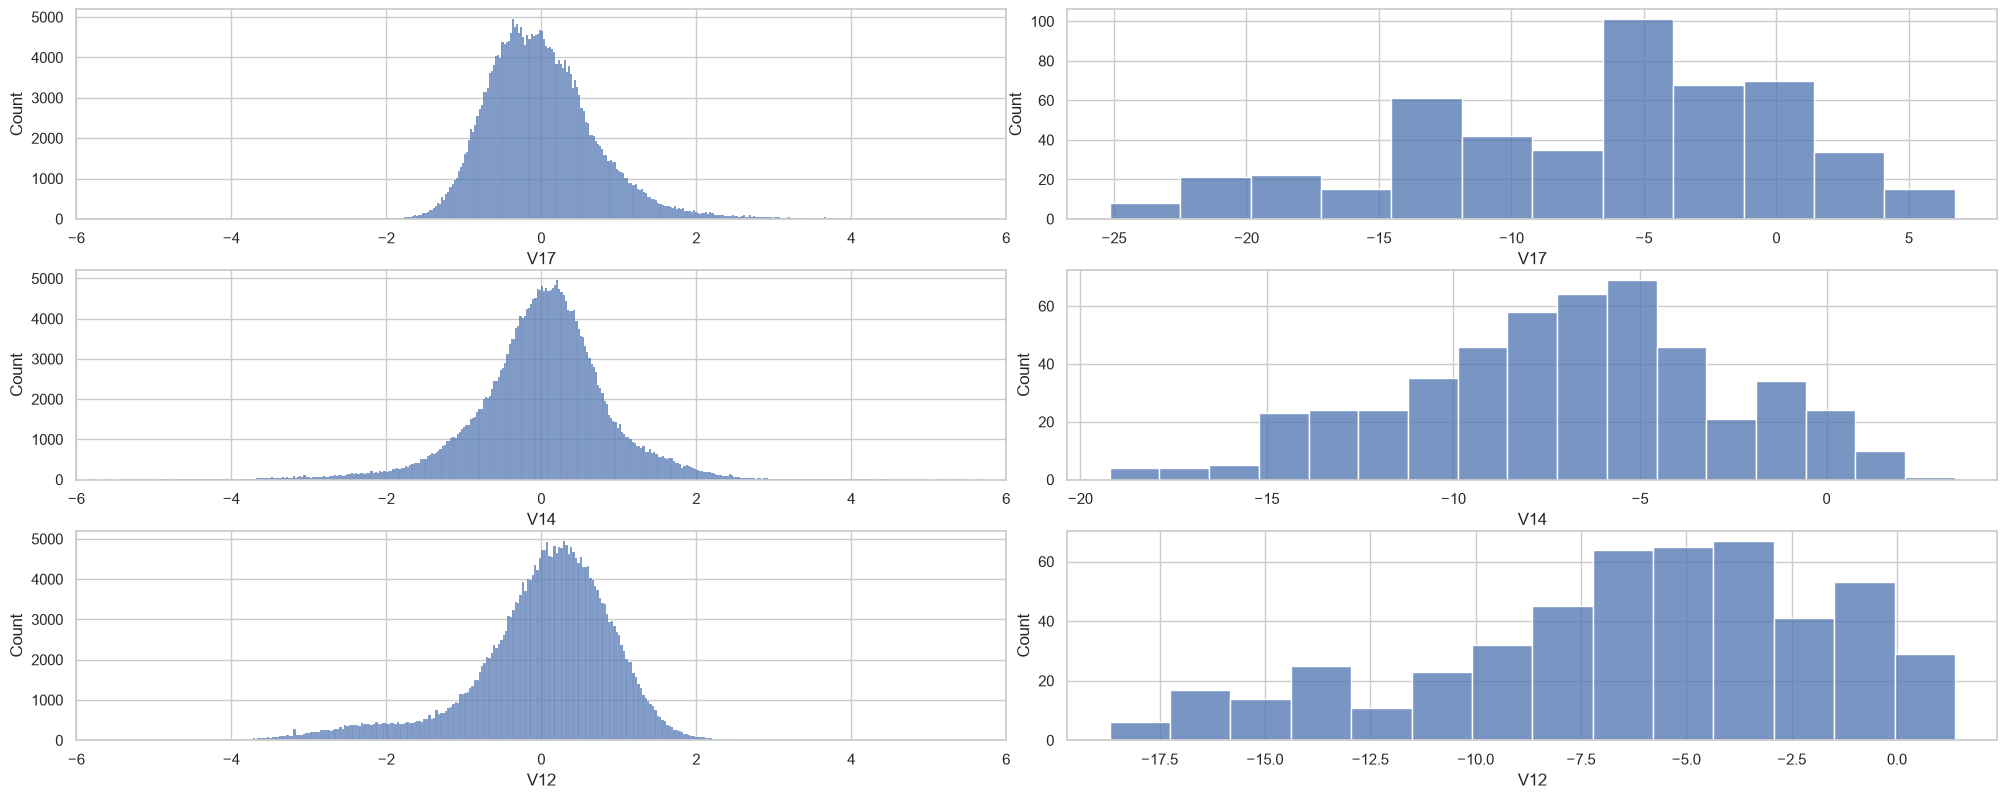

In [8]:
#your code here
res_corr = df.corrwith(df["Class"])
res_corr = abs(res_corr).sort_values(ascending=False)
best_3 = res_corr.index[1:4].values
fig, ax = plt.subplots(3, 2, figsize=(20, 8))
plt.tight_layout()
sns.set_style("darkgrid")

for i in range(3):
    cur_col = best_3[i]
    mask = (df["Class"] == 0)
    sns.histplot(df[mask], x=cur_col, ax=ax[i, 0])
    ax[i, 0].set_xlim([-6, 6])
    sns.histplot(df[~mask], x=cur_col, ax=ax[i, 1])

Теперь давайте разделим данные. Отделите хронологически последние 20% транзакций и поделите их пополам (также хронологически, т.е. без перемешивания) на валидационные и тестовые. Это разбиение не совсем корректно (как можно было заметить, мошеннические транзакции имеют разное распределение во времени - по-хорошему, нам стоило бы выделить целые сутки записей как под валидацию, так и под тест), тем не менее, мы не сможем получить больше данных для адекватного контроля, поэтому обойдемся этим. 

In [9]:
#your code here
import sklearn as sk
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class"])
y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5)

# Часть 1. Несбалансированная классификация.

**Задание 0. (1 балл)**: перед началом работы давайте поговорим о том, как мы будем оценивать качество. Классические метрики для качества классификации чаще всего "ломаются" на задачах с сильным перекосом. Чему будет равно значение accuracy для наивного предсказания (= мажорный класс для каждого объекта)? (можете не отвечать, просто подумайте)

Из курса МО-1 вам уже известно, что мы можем использовать в таких задачах `AUC-PR` и получать адекватные показатели. Можно сказать, что `AUC-PR` представляет собой матожидание `precision` по распределению, заданному выигрышем в `recall` при смене порога. 

In [10]:
#your code here
from sklearn.metrics import average_precision_score

Тем не менее, существуют и другие, не менее интересные метрики. Одной из таких метрик является коэффициент Каппа Коэна, представляющий собой нормализованную `accuracy`:

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

Данная метрика служит в качестве меры согласованности между двумя независимыми предсказателями, но ничего не знает про "верные" и "предсказанные" метки (в отличие от многих других метрик машинного обучения). Здесь $p_o$ - доля согласованных предсказаний, а $p_e$ - доля согласованных предсказаний, которая могла бы получиться при случайных ответах предсказателей. В нашем случае это работает так:

• В качестве $p_o$ берем accuracy

• В качестве $p_e$ примем следующую величину - вероятность случайного соглашения позитивных ответов (произведение долей позитивных ответов в обоих предсказаниях) плюс вероятность случайного соглашения негативных ответов (произведение долей негативных ответов в обоих предсказаниях)

Метрика принимает значения от -1 до 1, где 1 - полная согласованность, 0 - согласованность на уровне рандома, -1 - совсем плохо. Как уже говорилось, метрика не различает "верные" и "предсказанные" метки, поэтому является симметричной (можете использовать это для отладки):

In [11]:
#your code here
from sklearn.metrics import accuracy_score

def k_metric(true, preds):
    p_0 = accuracy_score(true, preds)
    p_true = true.mean()
    p_preds = preds.mean()

    p_e = (p_true * p_preds) + ((1 - p_true) * (1 - p_preds))

    if p_e == 1:
        return 1
    return (p_0 - p_e) / (1 - p_e)

Еще одной метрикой в такой задаче служит коэффициент корреляции Мэтьюза, выражающийся в терминах матрицы ошибок следующим образом:

$
\text{MCC} = \frac{TP\times TN - FP \times FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$ 

Метрика принимает значения от -1 до 1, интерпретируемые аналогичным образом. 

In [12]:
#your code here
from sklearn.metrics import matthews_corrcoef

Обратите внимание, что эти метрики вычисляются на бинаризованных предсказаниях, поэтому может иметь смысл дополнительная настройка порога бинаризации.

Давайте проверим, что наши метрики действительно подходят под задачу. Вычислите их значения для наивного предсказания (aka мажорный класс для всех объектов):

In [13]:
#your code here
from sklearn.metrics import cohen_kappa_score
preds = np.zeros(df.shape[0])

print(f"K: {cohen_kappa_score(df["Class"], preds)} | {k_metric(df["Class"], preds)}")
print(f"MCC: {matthews_corrcoef(df["Class"], preds)}")
print(f"PR-curve: {average_precision_score(df["Class"], preds)}")

K: 0.0 | 0.0
MCC: 0.0
PR-curve: 0.001727485630620034


Давайте запустим бейзлайн-решение для нашей задачи. С чего же начнем? Возьмите `catboost` и обучите его классификатор на наших данных (используйте все признаки). Вычислите значения всех метрик на тестовой части, для контроля переобучения используйте валидационную (здесь и далее везде, где фигурирует `catboost`). 

In [14]:
from catboost import CatBoostClassifier

In [15]:
#your code here
model = CatBoostClassifier(
    silent=True,
    early_stopping_rounds=50,
    random_seed = 42
)
model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    verbose=100
)

Learning rate set to 0.121128
0:	learn: 0.3193594	test: 0.3164131	best: 0.3164131 (0)	total: 176ms	remaining: 2m 55s
100:	learn: 0.0014806	test: 0.0027994	best: 0.0027786 (99)	total: 1.96s	remaining: 17.4s
200:	learn: 0.0010293	test: 0.0027222	best: 0.0027201 (198)	total: 3.4s	remaining: 13.5s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.002703063772
bestIteration = 247

Shrink model to first 248 iterations.


CatBoostClassifier(early_stopping_rounds=50, random_seed=42, silent=True)

In [16]:
preds = model.predict(X_test)

print(f"K: {k_metric(y_test, preds)}")
print(f"MCC: {matthews_corrcoef(y_test, preds)}")
print(f"PR-curve: {average_precision_score(y_test, preds)}")

K: 0.8194813613328508
MCC: 0.824942565943746
PR-curve: 0.6811438868506843


Если вы все сделали правильно, у вас должны были получиться значения в районе 0.7.

**Задание 1. (1 балл)**. Многие реализации методов предлагают встроенные способы для борьбы с нашей проблемой. Самое часто встречающееся решение - просто добавить вес в функции потерь для минорного класса (таким образом, ошибка на объекте минорного класса будет весить больше, чем для мажорного). В `catboost` это также реализовано, причем для бинарной задачи это можно сделать целыми двумя способами (можете выбрать любой, на свой вкус, автор задания предпочитает отдельный скейлинг для минорного класса). Чаще всего в качестве веса берется отношение числа объектов мажорного класса к числу минорного. Попробуйте обучить модель с таким скалированием и сравните метрики на тестовой части с бейзлайном.

In [17]:
#your code here
class_1 = df["Class"].sum()
w = (df.shape[0] - class_1) / class_1

model = CatBoostClassifier(
    iterations=300,
    class_weights=[1.0, w],
    loss_function="Logloss",
    eval_metric='PRAUC',
    early_stopping_rounds = 30
)
model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    verbose=75
)
preds = model.predict(X_test)
preds_proba = model.predict_proba(X_test)[:, 1]

print(f"K: {k_metric(y_test, preds)}")
print(f"MCC: {matthews_corrcoef(y_test, preds)}")
print(f"PR-curve: {average_precision_score(y_test, preds_proba)}")

Learning rate set to 0.204502
0:	learn: 0.9756654	test: 0.9082537	best: 0.9082537 (0)	total: 27.1ms	remaining: 8.1s
75:	learn: 0.9999662	test: 0.9789662	best: 0.9831148 (52)	total: 3.3s	remaining: 9.74s
Stopped by overfitting detector  (30 iterations wait)

bestTest = 0.9831148008
bestIteration = 52

Shrink model to first 53 iterations.
K: 0.6742396289742916
MCC: 0.6855601831428171
PR-curve: 0.8177762483728211


Поскольку данный вес будет являться гиперпараметром метода, было бы опрометчиво остановиться на одном значении (тем более, с большой вероятностью у вас все сломалось). Запустите перебор для этого гиперпараметра на валидационной выборке (используйте `PR-AUC`), подберите оптимальный порог бинаризации для $\kappa$ или $\text{MCC}$. Для лучшего найденного веса и порога вычислите все метрики на тестовой части. 

При этом можете также проверить отдельное скалирование в большую сторону для мажорного класса (т.е. веса минорного сделать меньше 1) и экстремальные скалирования (т.е. веса минорного больше, чем в начале этого задания). Какой вес получился оптимальным?

In [18]:
#your code here
weights = np.logspace(0, 3, 12)
pr = []

for w in weights:
    model = CatBoostClassifier(
        iterations=300,
        class_weights=[1.0, w],
        loss_function="Logloss",
        eval_metric='PRAUC',
        early_stopping_rounds = 30,
        silent=True
    )
    model.fit(
        X_train, y_train,
        eval_set=(X_val, y_val),
    )
    preds = model.predict_proba(X_test)[:, 1]
    pr.append(average_precision_score(y_test, preds))

In [19]:
best_w = weights[np.argmax(pr)]
model = CatBoostClassifier(
    iterations=300,
    class_weights=[1.0, best_w],
    loss_function="Logloss",
    eval_metric='PRAUC',
    early_stopping_rounds = 30,
    silent=True
)
model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
)
proba = model.predict_proba(X_test)[:, 1]

thresholds = np.logspace(-2, 0, 30)
mcc = []

for thr in thresholds:
    preds = (proba >= thr)
    mcc.append(matthews_corrcoef(y_test, preds))
best_thr = thresholds[np.argmax(mcc)]

preds = (proba >= best_thr)

print(f"K: {k_metric(y_test, preds)}")
print(f"MCC: {matthews_corrcoef(y_test, preds)}")
print(f"PR-curve: {average_precision_score(y_test, proba)}")

K: 0.874859947362171
MCC: 0.8765775342168001
PR-curve: 0.8246753303719049


**Задание 2. (1 балл)**. На самом деле, то, что мы сейчас делали, очень схоже с другой распространенной техникой - оверсэмплингом. Фактически, мы можем продублировать все объекты минорного класса и получить тот же эффект, какой был бы при использовании веса, равного 2. Тем не менее, такой подход - это лишь малая часть того, что мы можем проделать с целью повысить число объектов минорного класса. 

Для продолжения работы установим библиотеку [imbalanced-learn](https://imbalanced-learn.org/stable/):

Первый метод, которым мы воспользуемся, называется SMOTE (его вы уже разбирали на лекции). Кратко напомним суть: мы выбираем случайного кандидата среди $k$ ближайших соседей объекта минорного класса, затем берем точку на отрезке между двумя объектами (т.е. выпуклую комбинацию со случайными коэффициентами) и добавляем в выборку. 

In [20]:
from imblearn.over_sampling import SMOTE

Используйте SMOTE для ресэмплинга обучающей выборки, на новой выборке обучите модель (вес положительных объектов скалировать не нужно). Замерьте качество на тестовой выборке (**важно!** не преобразовывайте валидационную и тестовую выборку никак - мы не хотим отслеживать качество на объектах, которых в реальности не существует). Сравните полное выравнивание выборки с частичным (т.е. таким, что баланс классов улучшается, но не достигает равенства - скажем, 1:2 и 1:10).

In [21]:
#your code here
smote = SMOTE(sampling_strategy=0.33) #1:2
X_train_r, y_train_r = smote.fit_resample(X_train, y_train)

model = CatBoostClassifier(
    silent=True,
    early_stopping_rounds=50,
    random_seed = 42
)
model.fit(
    X_train_r, y_train_r,
    eval_set=(X_val, y_val),
    verbose=100
)

preds = model.predict(X_test)

print(f"K: {k_metric(y_test, preds)}")
print(f"MCC: {matthews_corrcoef(y_test, preds)}")
print(f"PR-curve: {average_precision_score(y_test, preds)}")

Learning rate set to 0.129909
0:	learn: 0.4121552	test: 0.4168671	best: 0.4168671 (0)	total: 28.1ms	remaining: 28s
100:	learn: 0.0077729	test: 0.0039713	best: 0.0039713 (100)	total: 2.13s	remaining: 19s
200:	learn: 0.0027432	test: 0.0031307	best: 0.0031307 (200)	total: 4.07s	remaining: 16.2s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.003130658755
bestIteration = 200

Shrink model to first 201 iterations.
K: 0.8233184932144045
MCC: 0.8233184932144194
PR-curve: 0.6784113588018188


In [22]:
#your code here
smote = SMOTE(sampling_strategy=0.0909) #1:10
X_train_r, y_train_r = smote.fit_resample(X_train, y_train)

model = CatBoostClassifier(
    silent=True,
    early_stopping_rounds=50,
    random_seed = 42
)
model.fit(
    X_train_r, y_train_r,
    eval_set=(X_val, y_val),
    verbose=100
)

preds = model.predict(X_test)

print(f"K: {k_metric(y_test, preds)}")
print(f"MCC: {matthews_corrcoef(y_test, preds)}")
print(f"PR-curve: {average_precision_score(y_test, preds)}")

Learning rate set to 0.123704
0:	learn: 0.4142770	test: 0.3971700	best: 0.3971700 (0)	total: 21.1ms	remaining: 21s
100:	learn: 0.0071872	test: 0.0039688	best: 0.0039679 (99)	total: 2.22s	remaining: 19.8s
200:	learn: 0.0023321	test: 0.0028822	best: 0.0028502 (192)	total: 4.28s	remaining: 17s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.002850215446
bestIteration = 192

Shrink model to first 193 iterations.
K: 0.8057417091337977
MCC: 0.8058316818869857
PR-curve: 0.6499783982078681


**Бонус (1.5 балла)**. Для vanilla SMOTE существуют некоторые модификации, часть из которых была реализована в библиотеке imblearn. Во время лекций/семинаров эти модификации не рассматривались, тем не менее, мы все равно их исследуем.

Найдите статьи о следующих методах и попробуйте вкратце сформулировать, в чем их основная идея (сделайте так, чтобы человек, знакомый с машинным обучением в целом, но не слышавший конкретно про это смог понять):

BorderlineSMOTE - 

SVM-SMOTE - 

K-Means-SMOTE - 

ADASYN - 

Теперь попробуйте сравнить качество всех методов на наших данных.

In [23]:
#your code here

**Задание 3. (1 балл)**. До этого момента все наши решения концентрировались на работе с минорным классом. Теперь давайте попробуем зайти с другой стороны. Может быть, для восстановления закономерностей нам не нужно столько объектов мажорного класса, и они просто засоряют нам выборку лишней информацией?

Для решения этой проблемы существуют методы андерсэмплинга. Самое простое, что можно придумать - удалять точки мажорного класса, пока мы не получим приемлемый баланс. Протестируйте следующий метод и постройте графики достигаемых значений метрик от баланса классов и от отношения размеров исходной и пересэмпленной выборки:

In [24]:
from imblearn.under_sampling import RandomUnderSampler

In [25]:
#your code here

ls = np.linspace(0.05, 1, 20)
scores = []

for ratio in ls:
    und = RandomUnderSampler(sampling_strategy=float(ratio), random_state=42)
    X_resampled, y_resampled = und.fit_resample(X_train, y_train)

    model = CatBoostClassifier(
        iterations=250,
        silent=True,
        early_stopping_rounds=50,
        eval_metric='PRAUC',
        random_seed = 42
    )
    model.fit(
        X_resampled, y_resampled,
        eval_set=(X_val, y_val)
    )
    proba = model.predict_proba(X_test)[:, 1]
    scores.append(average_precision_score(y_test, proba))

<Axes: >

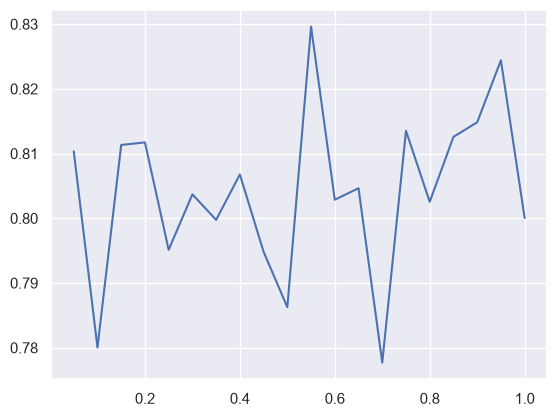

In [26]:
sns.lineplot(x=ls, y=scores)

Даже такой наивный подход может дать относительно неплохие результаты и улучшить наши метрики. Тем не менее, сейчас мы никак не используем информацию о распределении объектов в выборке. Оказывается, что даже относительно простые эвристические правила могут заметно поднять нам качество - например, мы можем при отбрасывании использовать близость отдельных объектов мажорного класса к минорному и отбрасывать самые близкие. Протестируйте алгоритм [Near-Miss](https://www.site.uottawa.ca/~nat/Workshop2003/jzhang.pdf) на наших данных и постройте графики, аналогичные предыдущему пункту (также добавьте график с зависимостью качества от числа соседей).

<Axes: >

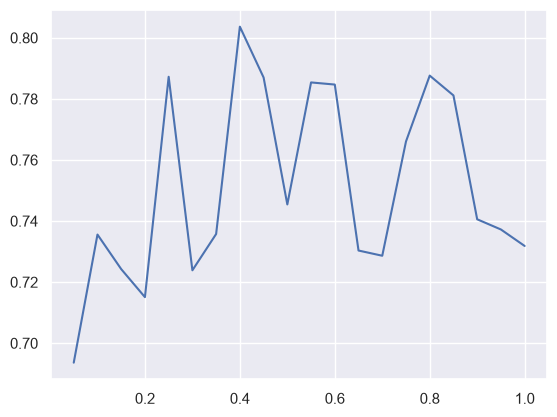

In [27]:
from imblearn.under_sampling import NearMiss

#your code here
ls = np.linspace(0.05, 1, 20)
scores = []

for ratio in ls:
    nm = NearMiss(sampling_strategy=float(ratio))
    X_resampled, y_resampled = nm.fit_resample(X_train, y_train)

    model = CatBoostClassifier(
        iterations=250,
        silent=True,
        early_stopping_rounds=50,
        eval_metric='PRAUC',
        random_seed = 42
    )
    model.fit(
        X_resampled, y_resampled,
        eval_set=(X_val, y_val)
    )
    proba = model.predict_proba(X_test)[:, 1]
    scores.append(average_precision_score(y_test, proba))
sns.lineplot(x=ls, y=scores)

<Axes: >

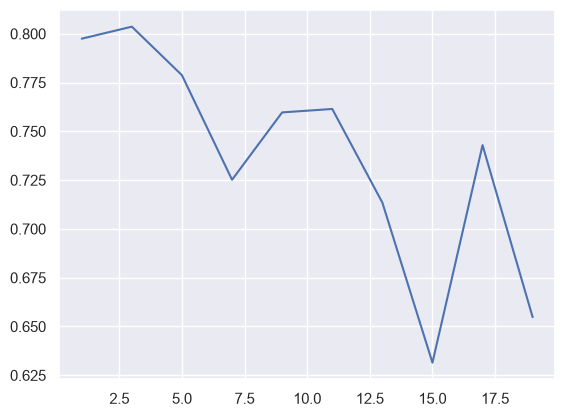

In [28]:
from imblearn.under_sampling import NearMiss

#your code here
nn = np.arange(1, 20, 2)
scores = []

for k in nn:
    nm = NearMiss(sampling_strategy=0.4, n_neighbors=k)
    X_resampled, y_resampled = nm.fit_resample(X_train, y_train)

    model = CatBoostClassifier(
        iterations=250,
        silent=True,
        early_stopping_rounds=50,
        eval_metric='PRAUC',
        random_seed = 42
    )
    model.fit(
        X_resampled, y_resampled,
        eval_set=(X_val, y_val)
    )
    proba = model.predict_proba(X_test)[:, 1]
    scores.append(average_precision_score(y_test, proba))
sns.lineplot(x=nn, y=scores)

Выглядит лучше чем random undersampling. Увеличение соотношения сказывается на PR AUC немного сильнее и имеет меньший разброс. Оптимальное количество соседей также можно подбирать методом локтя.

**Бонус (1 балл)**. imblearn также предлагает много различных методов для андерсэмплинга. Выберите что-нибудь еще из предлагаемого на свой вкус, опишите идею метода и протестируйте его.

**Бонус (2 балла)**. Сможете ли вы с помощью комбинации любых методов оверсэмплинга, андерсэмплинга и классификации набрать 0.8 на всех трех метриках?

# Часть 2. Поиск аномалий. 

Как вы могли заметить, методы балансировки выборок очень часто могут привести к не самым лучшим результатам из-за того, что они по сути искажают информацию о реальном распределении данных - в реальности обычно требуется долгий подбор в принципе работоспособных для задачи методов и их аккуратная настройка. 

Теперь давайте попробуем слегка сменить постановку задачи и переключиться на задачу "одноклассовой" классификации, то есть - поиска *аномалий* в выборке. В общем-то, это вполне согласуется с нашей областью работы - мы действительно можем назвать мошеннические транзакции аномальньми (как интуитивно, так и на основании наблюдаемой балансировки данных). 

Стоит отметить, что методы обнаружения аномалий чаще всего относятся к классу методов обучения без учителя. Это дает некоторый положительный эффект - нам не обязательно нужно тратить время на разметку данных (тем не менее, для контроля качества какую-то часть разметить все-таки придется). Впрочем, чаще всего перфоманс таких методов оказывается заметно хуже, чем у честного обучения с учителем (если мы можем себе его позволить).



**Задание 4. (3 балла).** На занятиях вы разбирали схожий с Random Forest подход для детекции аномалий без известной разметки данных, называемый Isolation Forest. Напомним суть: на этапе обучения мы создаем ансамбль из решающих деревьев, в котором признак и порог на каждую вершину подбираются случайно. Затем мы считаем для объектов оценку аномальности через длину пути до соответствующего листа в каждом дереве.

В данном задании вам предлагается реализовать модификацию данного алгоритма, известную как Extended Isolation Forest. В ней мы на каждом шаге будем определять не порог для признака, а полноценную случайную гиперплоскость, разбивающую выборку на 2 части. С детальным описанием вы можете ознакомиться [здесь](https://arxiv.org/pdf/1811.02141.pdf).

Ниже приведен шаблон кода. Постарайтесь работать в его рамках (минорные изменения вполне допустимы, главное не переворачивайте всю структуру с ног на голову). 

**NB**: будем считать, что в нашем датасете нет категориальных признаков - можете не заморачиваться с их обработкой (но в общем случае, это будет важно).

**Советы**:
 - Численные признаки лучше предобработать надлежащим образом.
 - Возможно, вам поможет выбрасывание некоторых признаков.
 - Внимательно следите за знаками.
 - Не игнорируйте документирующие строки.
 - Вероятнее всего, вы не сможете приблизиться по качеству к supervised-решениям. Если у вас не получается это сделать (но вы уверены в своей правоте), не стоит тратить слишком много времени на поиск ошибок.



**Бонусы (каждый по 0.5)**:
- Сделайте ваш EIF параллельным (`multiprocessing`, `joblib`).
- Добавьте возможность откатиться к дефолтному варианту Isolation Forest. (порассуждайте, как можно реализовать это в данной модели?):


In [29]:
import numpy as np

def c_factor(n):
    """
    Computes average path length for an unsuccessful search in a binary search tree.
    Params:
        n: int - number of data points for BST
    """
    if n <= 1:
        return 0.0
    if n == 2:
        return 1.0
    h = 0.5772156649 + np.log(n - 1)
    return 2.0 * h - 2.0 * (n - 1) / n

def calc_height(X, depth, node):
    """
    Calculates anomaly scores for sample in a recursive manner.
    Params:
        X: np.array - current sample, available to node
        depth: int - path length up to current node
        node: Node - current tree node
        
    Returns:
        scores: int, float or np.array - anomaly scores for sample
    """
    scores = np.zeros(X.shape[0])

    if node.kind == "external" or node.left is None or node.right is None:
        return depth + c_factor(node.size)

    projections = np.dot(X, node.w)
    left_mask = projections < node.b

    if np.any(left_mask):
        scores[left_mask] = calc_height(X[left_mask], depth + 1, node.left)
    if np.any(~left_mask):
        scores[~left_mask] = calc_height(X[~left_mask], depth + 1, node.right)

    return scores


class Node(object):
    """
    A single node object for each tree. Contains information on height, current data,
    splitting hyperplane and children nodes.
    
    Attributes:
        X: np.array - data available to current node
        size: int - length of available data
        depth: int - depth of node
        left: Node - left child
        right: Node - right child
        kind: str - either "internal" or "external", indicates the type of current node
        w: np.array - normal vector for the splitting hyperplane
        b: float - intercept term for the splitting hyperplane
    """
    def __init__(self, X, depth, left, right, kind, w, b):
        """
        Node(h, left, right, kind, w, b)
        Represents the node object.
        
        Params:
            X: np.array - data available to current node
            depth: int - depth of node
            left: Node - left child
            right: Node - right child
            kind: str - either "internal" or "external", indicates the type of current node
            w: np.array - normal vector for the splitting hyperplane
            b: float - intercept term for the splitting hyperplane
        """
        self.size = len(X)
        self.depth = depth
        self.left = left
        self.right = right
        self.kind = kind
        self.w = w
        self.b = b
    
    def __repr__(self):
        """
        For convenience only.
        """
        return f"Node(size={self.size}, depth={self.depth}, kind={self.kind})"


class RandomizedTree(object):
    """
    Single randomized tree object. Stores root and its depth (tree is built recursively).
    Attributes:
        depth: int - current tree depth
        max_depth: int - maximum tree depth
        root: Node - root node 
        internal_count: int - number of internal nodes
        external_count: int - number of external nodes
    """
    def __init__(self, X, max_depth):
        """
        Single randomized tree object. Stores root and its depth (tree is built recursively).
        Params:
            X: np.array - train sample
            max_depth: int - maximum tree depth
        """
        self.depth = 0
        self.max_depth = max_depth
        
        self.internal_count = 0
        self.external_count = 0

        self.root = self.grow(X, 0)
        self.depth = self._get_max_depth(self.root)
        
    def __repr__(self):
        """
        For convenience only.
        """
        return f"RandomizedTree(depth={self.depth}, max_depth={self.max_depth}, n_internal={self.internal_count}, n_external={self.external_count})"

    def _get_max_depth(self, node):
        if node is None or node.kind == "external":
            return node.depth if node else 0
        return max(self._get_max_depth(node.left), self._get_max_depth(node.right))
        
    def grow(self, X, depth):
        """
        Grow tree in a recursive manner.
        Params:
            X: np.array - available train sample
            depth: int - current tree depth
            
        Returns:
            node: Node - a trained node with separating hyperplane data.
        """
        n, d = X.shape

        # Stopping criteria
        if n <= 1 or depth >= self.max_depth or np.all(X == X[0]):
            self.external_count += 1
            return Node(X=X, depth=depth, left=None, right=None, kind="external", w=None, b=None)
        
        self.internal_count += 1

        # Random normal vector for Extended Isolation Forest hyperplane split
        w = np.random.randn(d)
        w_norm = np.linalg.norm(w)
        if w_norm == 0:
            w = np.ones(d) / np.sqrt(d)
        else:
            w /= w_norm

        projections = np.dot(X, w)
        p_min, p_max = np.min(projections), np.max(projections)

        if p_min == p_max:
            self.external_count += 1
            return Node(X=X, depth=depth, left=None, right=None, kind="external", w=None, b=None)

        b = np.random.uniform(p_min, p_max)
        left_mask = projections < b

        if not np.any(left_mask) or np.all(left_mask):
            self.external_count += 1
            return Node(X=X, depth=depth, left=None, right=None, kind="external", w=None, b=None)

        left_child = self.grow(X[left_mask], depth + 1)
        right_child = self.grow(X[~left_mask], depth + 1)

        return Node(X=X, depth=depth, left=left_child, right=right_child, kind="internal", w=w, b=b)

    def score_samples(self, X):
        """
        Calculate anomaly scores for given data. You may utilize outer function `calc_height`.
        Params:
            X: np.array - data to be evaluated
            
        Returns:
            scores: np.array - estimated anomaly scores
        """
        return calc_height(X, 0, self.root)
        
    
class ExtendedIsolationForest(object):
    """
    Extended Isolation Forest object. Stores training data and trained randomized trees.
    Attributes:
        n_trees: int - number of Randomized Trees
        max_depth: int - maximum depth of each tree
        subsample_rate: float - draw `subsample_rate * X.shape[0]` samples for each tree
        trees: list - container for trained trees 
        contamination: float - estimated fraction of anomaly samples in data. Used for thresholding
    """
    def __init__(self, n_trees, subsample_rate, max_depth=None, contamination=0.01):
        """
        Extended Isolation Forest object. Stores training data and trained randomized trees.
        Params:
            n_trees: int - number of Randomized Trees
            subsample_rate: float - draw `subsample_rate * X.shape[0]` samples for each tree
            max_depth: int or None - maximum depth of each tree. Defaults to ceil(log_2(subsample_size)) if not provided
            contamination: float - estimated fraction of anomaly samples in data. Used for thresholding
        """
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.subsample_rate = subsample_rate
        self.trees = []
        self.contamination = contamination
        self.is_fit = False
        
    def __repr__(self):
        """For convenience only."""
        return f"ExtendedIsolationForest(n_trees={self.n_trees}, max_depth={self.max_depth}, subsample_rate={self.subsample_rate}, contamination={self.contamination}, is_fit={self.is_fit})"
        
    def fit(self, X):
        """
        Fit EIF to new data.
        Params:
            X: np.array - 2d array of samples
        """
        X = np.array(X)
        n_samples = X.shape[0]
        subsample_size = int(self.subsample_rate * n_samples)
        subsample_size = max(subsample_size, 2)

        if self.max_depth is None:
            self.max_depth = int(np.ceil(np.log2(subsample_size)))

        self.trees = []
        for _ in range(self.n_trees):
            indices = np.random.choice(n_samples, size=subsample_size, replace=False)
            subsample = X[indices]
            tree = RandomizedTree(subsample, self.max_depth)
            self.trees.append(tree)

        self.is_fit = True
        return self
    
    def score_samples(self, X):
        """
        Estimate (normalized) anomaly score for each given sample
        Params:
            X: np.array - new samples

        Returns:
            scores: np.array - anomaly scores (larger value means higher probability of a sample being an outlier)
        """
        X = np.array(X)
        if not self.is_fit:
            raise ValueError("Model has not been fitted yet.")

        paths = np.zeros(X.shape[0])
        for tree in self.trees:
            paths += tree.score_samples(X)
        paths /= self.n_trees

        subsample_size = int(self.subsample_rate * X.shape[0])
        subsample_size = max(subsample_size, 2)
        c_n = c_factor(subsample_size)

        if c_n == 0:
            scores = np.zeros(X.shape[0])
        else:
            scores = 2.0 ** (-paths / c_n)

        return scores
    
    def predict(self, X):
        """
        Predict if given samples are outliers.
        Params:
            X: np.array - new samples

        Returns:
            labels: np.array - anomaly labels (1 for outliers, 0 for inliers)
        """
        scores = self.score_samples(X)
        threshold = np.percentile(scores, 100 * (1 - self.contamination))
        labels = (scores > threshold).astype(int)
        return labels

Лень писать самому полностью, логика похожа на dtree но разделение вершинок другое.

**Задание 5. (1 балл).** Протестируйте вашу реализацию EIF и подберите оптимальные гиперпараметры (наш метод не использует разметку, поэтому можете попробовать делать это на обучающей выборке). Сравните ее с обычным IF из `sklearn` (желательно делать это на одних и тех же параметрах). Удалось ли сделать лучше?

In [30]:
from sklearn.ensemble import IsolationForest

model = ExtendedIsolationForest(n_trees=75, subsample_rate=0.4, contamination=0.01)
model.fit(X[:10000])
preds = model.predict(X[:10000]) # 0 - normal, 1 - anomaly
model_sk = IsolationForest(n_estimators=75, random_state=42, max_features=0.4, contamination=0.01)
preds_sk = model_sk.fit_predict(X[:10000])
preds_sk = np.where(preds_sk == -1, 1, 0) #0 - anomaly, 1 - normal

print(f"Total class=1: {y[:10000].sum()}")
print(f"Difference between result and labels(sklearn): {(y[:10000] != preds_sk).sum()}")
print(f"Difference between result and labels: {(y[:10000] != preds).sum()}")

Total class=1: 38
Difference between result and labels(sklearn): 80
Difference between result and labels: 136


В целом Extended IF работает неплохо, но выдаёт результат хуже чем реализация из sklearn. На больших значениях contamination разницы почти нет, но на маленьких она значительна.

Возможно, ваш алгоритм выдал большие оценки объектам с негативной разметкой. Постарайтесь выбрать несколько таких объектов и доступно объяснить (= с кодом и графиками), почему так вышло:

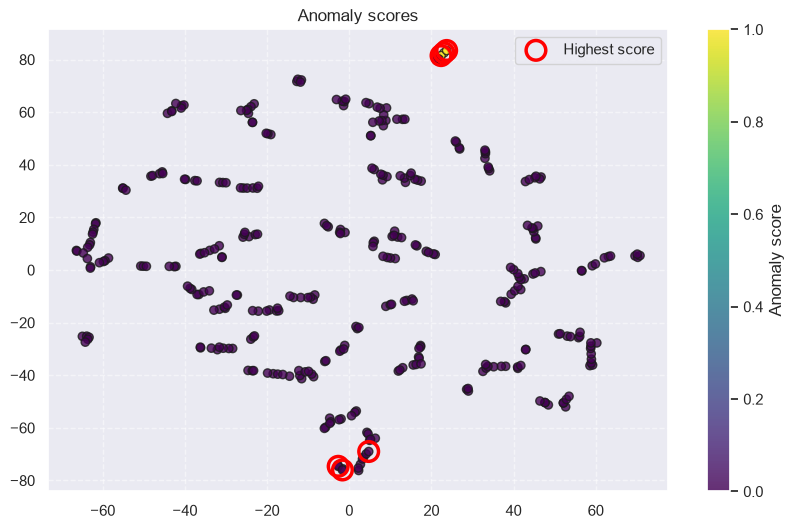

In [31]:
from sklearn.manifold import TSNE

X_true = X.copy()
y_true = y.copy()
X = X[:350]
model = ExtendedIsolationForest(n_trees=50, subsample_rate=0.1)
model.fit(X)
preds = model.predict(X)

X_embedded = TSNE(n_components=2, learning_rate='auto',
                  init='random', perplexity=3).fit_transform(X)

mask = (y == 0)[:350]
preds_zip = np.array( list(zip(preds, np.arange(0, len(preds), 1))) )
top_6 = sorted(preds_zip[mask], key = lambda x : x[0])[-6:]
top_6_idx = list(zip(*top_6))[1]

plt.figure(figsize=(10, 6))

scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=preds, cmap='viridis', edgecolor='k', alpha=0.8)
plt.colorbar(scatter, label='Anomaly score')

plt.scatter(X_embedded[top_6_idx, 0], X_embedded[top_6_idx, 1], 
            s=200, facecolors='none', edgecolors='red', linewidths=2.5, 
            label='Highest score')

plt.title('Anomaly scores')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

X = X_true
y = y_true

IF отрезает объекты или маленькие кластеры с краю быстрее, из-за этого можно получить высокий score на объектах с негативной разметкой

**Задание 6. (1 балл).** `sklearn` также предлагает нам и другие методы для поиска аномалий. В этом задании мы предлагаем вам сделать следующее:

Для начала попробуйте использовать методы Local Outlier Factor и One-Class SVM. Сравните результаты с IF и EIF.  

In [32]:
#your code here
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

X_smol = X[:10000]
y_smol = y[:10000]
lof = LocalOutlierFactor(contamination=0.01) #-1 for outliers
preds_lof = lof.fit_predict(X_smol)
preds_lof = np.where(preds_lof == -1, 1, 0)
ocs = OneClassSVM(nu=0.01) #-1 for outliers
preds_ocs = ocs.fit_predict(X_smol)
preds_ocs = np.where(preds_ocs == -1, 1, 0)

print(f"Total class=1: {y_smol.sum()}")
print(f"Different labels count(lof): {(preds_lof != y_smol).sum()}")
print(f"Different labels count(ocs): {(preds_ocs != y_smol).sum()}")

Total class=1: 38
Different labels count(lof): 134
Different labels count(ocs): 136


У вас началась депрессия из-за плохих метрик? Не беда! Сейчас давайте сделаем так: все методы, опробованные в этой части, попробуем задействовать для создания дополнительных признаков в данных. Проделайте это (не забудьте, что обучаться здесь нужно на трейне). Теперь возьмите лучшую модель из предыдущей части и обучите на новых данных. Смогли ли unsupervised-методы повысить вам качество?

In [33]:
#your code here
def append_unsup_features(df, y):
    df_res = df.copy()
    cont = 0.002 #Train proportion

    ocs = OneClassSVM(nu=cont)
    preds_ocs = ocs.fit_predict(df)
    preds_ocs = np.where(preds_ocs == -1, 1, 0)
    df_res['ocs'] = preds_ocs

    lof = LocalOutlierFactor(contamination=cont)
    preds_lof = lof.fit_predict(df)
    preds_lof = np.where(preds_lof == -1, 1, 0)
    df_res["lof"] = preds_lof

    model_sk = IsolationForest(n_estimators=50, random_state=42, max_features=0.1, contamination=cont)
    preds_sk = model_sk.fit_predict(df)
    preds_sk = np.where(preds_sk == -1, 1, 0)
    df_res["if"] = preds_sk
    return df_res

X_train_unsup, X_val_unsup, X_test_unsup = (
    append_unsup_features(X_train, y_train),
    append_unsup_features(X_val, y_val),
    append_unsup_features(X_test, y_test)
)

In [36]:
model = CatBoostClassifier(
    iterations=700,
    loss_function="Logloss",
    eval_metric='PRAUC',
    early_stopping_rounds = 100
)
model.fit(
    X_train_unsup, y_train,
    eval_set=(X_val_unsup, y_val),
    verbose=350
)

Learning rate set to 0.141458
0:	learn: 0.2772411	test: 0.0457580	best: 0.0457580 (0)	total: 19.5ms	remaining: 13.6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7836303299
bestIteration = 55

Shrink model to first 56 iterations.


CatBoostClassifier(early_stopping_rounds=100, eval_metric='PRAUC', iterations=700, loss_function='Logloss')

In [42]:
preds = model.predict_proba(X_test_unsup)

print(f"K: {k_metric(y_test, (preds[:, 1] > 0.5))}")
print(f"MCC: {matthews_corrcoef(y_test, (preds[:, 1] > 0.5))}")
print(f"PR-curve: {average_precision_score(y_test, preds[:, 1])}")

K: 0.8385355781844602
MCC: 0.8424985223780226
PR-curve: 0.8148824839124454


In [44]:
model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    verbose=350
)
preds = model.predict_proba(X_test)

print(f"K: {k_metric(y_test, (preds[:, 1] > 0.5))}")
print(f"MCC: {matthews_corrcoef(y_test, (preds[:, 1] > 0.5))}")
print(f"PR-curve: {average_precision_score(y_test, preds[:, 1])}")

Learning rate set to 0.141458
0:	learn: 0.1141053	test: 0.0772190	best: 0.0772190 (0)	total: 23.2ms	remaining: 16.2s
350:	learn: 0.9954736	test: 0.8290780	best: 0.8304002 (341)	total: 10.6s	remaining: 10.6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8304002039
bestIteration = 341

Shrink model to first 342 iterations.
K: 0.7997928641221212
MCC: 0.8070134864994686
PR-curve: 0.8116569356986573


Unsupervised методы немного подняли качество модели. Модель стала немного уверенее разделять позитивные классы и обучилась гораздо быстрее 341 итерация против 55

**Бонус. (0.1 балла).**

При сдаче проверяющий запустит следующую клетку один раз. Если она даст положительный результат, вы получите 0.1 бонусных балла. Если она даст отрицательный результат, вы получите -0.1 бонусных балла. 

Если вы хотите отказаться от сдачи данного задания, допишите "хочу" после двоеточия: `your text here`

Ниже вы можете попрактиковаться и оценить ваши силы (изменять код ячейки запрещается!)

In [34]:
import random

rng = random.SystemRandom(0)
rng.uniform(-1.0, 1.0)

-0.7515275129153667